In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

CSV_PATH = "employees.csv"

In [ ]:
df = pd.read_csv(CSV_PATH)              # lit le CSV dans un DataFrame

print("Dimensions (lignes, colonnes) :", df.shape)
print("\nColonnes :", list(df.columns))

print("\nTypes de données et nombre de valeurs non nulles par colonne :")
df.info()                               # dtype de chaque colonne + non-null count

print("\nPremières lignes :")
df.head()                               # affiche les 5 premières lignes

Dimensions (lignes, colonnes) : (1000, 8)

Colonnes : ['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary', 'Bonus %', 'Senior Management', 'Team']

Types de données et nombre de valeurs non nulles par colonne :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    object 
 1   Gender             855 non-null    object 
 2   Start Date         1000 non-null   object 
 3   Last Login Time    1000 non-null   object 
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    object 
dtypes: float64(1), int64(1), object(6)
memory usage: 62.6+ KB

Premières lignes :


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


In [ ]:
missing_original = df.isna().sum()      
print("Valeurs manquantes par colonne (données d'origine) :")
print(missing_original)

Valeurs manquantes par colonne (données d'origine) :
First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64


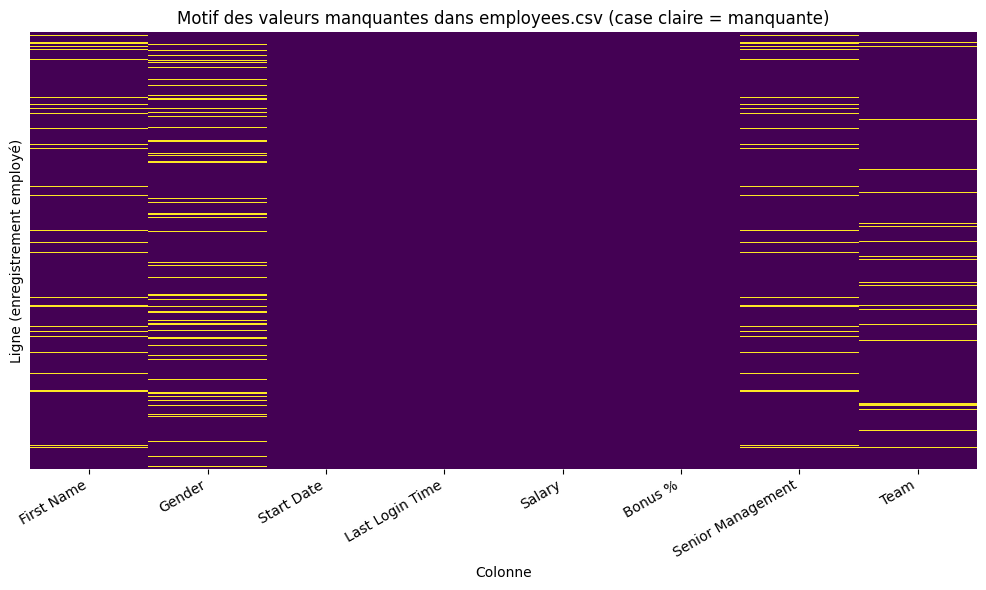

In [ ]:
plt.figure(figsize=(10, 6))                         # taille de la figure
sns.heatmap(
    df.isna(),                                      # matrice booléenne : True si NaN
    cbar=False,                                     # pas de barre de couleur (seulement 2 états)
    cmap="viridis",                                 # palette : une couleur pour présent, une pour manquant
    yticklabels=False,                              # on cache les 1000 numéros de lignes (illisibles)
)
plt.title("Motif des valeurs manquantes dans employees.csv (case claire = manquante)")
plt.xlabel("Colonne")
plt.ylabel("Ligne (enregistrement employé)")
plt.xticks(rotation=30, ha="right")                 # incline les noms de colonnes pour qu'ils restent lisibles
plt.tight_layout()
plt.show()

In [ ]:
df_marked = df.copy()                   # copie indépendante de l'original

synthetic_row = {
    "First Name": "-",                  # marqueur texte (pas reconnu comme manquant par pandas)
    "Gender": "na",                     # marqueur texte (idem)
    "Start Date": np.nan,               # vrai NaN
    "Last Login Time": np.nan,
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": np.nan,
    "Team": np.nan,
}

# Sécurité : les clés doivent correspondre exactement aux 8 colonnes du fichier
assert list(synthetic_row) == list(df.columns), "Les clés de la ligne doivent être les 8 colonnes"

# Ajoute la ligne à la fin (concat remplace l'ancien .append qui n'existe plus)
df_marked = pd.concat([df_marked, pd.DataFrame([synthetic_row])], ignore_index=True)

print("Nombre de lignes après ajout :", len(df_marked))
df_marked.tail(2)                       # affiche les 2 dernières lignes pour voir la ligne ajoutée

Nombre de lignes après ajout : 1001


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
999,Albert,Male,5/15/2012,6:24 PM,129949.0,10.169,True,Sales
1000,-,na,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
missing_marked = df_marked.isna().sum()

# Tableau comparatif : avant / après ajout de la ligne synthétique
pd.DataFrame({"original": missing_original, "avec_ligne_synthetique": missing_marked})

,original,avec_ligne_synthetique
First Name,67,67
Gender,145,145
Start Date,0,1
Last Login Time,0,1
Salary,0,1
Bonus %,0,1
Senior Management,67,68
Team,43,44


In [ ]:
# Marqueurs convenus (en minuscules, car la comparaison se fait en minuscules)
MISSING_MARKERS = {"-", "na", "n/a", "none", "null", "nan", ""}


def is_marker(value) -> bool:
    """True si la valeur est une chaîne qui correspond à un marqueur de valeur manquante."""
    return isinstance(value, str) and value.strip().casefold() in MISSING_MARKERS


df_clean = df_marked.copy()             # on garde df_marked intact pour pouvoir comparer

# On ne parcourt que les colonnes texte
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    # mask(condition, np.nan) : remplace par NaN là où la condition est vraie
    df_clean[col] = df_clean[col].mask(df_clean[col].map(is_marker), np.nan)

missing_clean = df_clean.isna().sum()

# Maintenant First Name et Gender ont bien +1
pd.DataFrame({"avec_ligne_synthetique": missing_marked, "apres_conversion_marqueurs": missing_clean})

,avec_ligne_synthetique,apres_conversion_marqueurs
First Name,67,68
Gender,145,146
Start Date,1,1
Last Login Time,1,1
Salary,1,1
Bonus %,1,1
Senior Management,68,68
Team,44,44


In [ ]:
def add_time_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Transforme les 2 colonnes date/heure (texte) en colonnes numériques."""
    out = frame.copy()

    # Start Date -> nombre de jours depuis le 1er janvier 1970
    start = pd.to_datetime(out["Start Date"], errors="coerce")      # texte invalide -> NaT (manquant)
    out["Start Days"] = (start - pd.Timestamp("1970-01-01")).dt.days

    # Last Login Time (ex. "12:42 PM") -> minutes écoulées depuis minuit
    login = pd.to_datetime(out["Last Login Time"], format="%I:%M %p", errors="coerce")
    out["Login Minutes"] = login.dt.hour * 60 + login.dt.minute

    return out.drop(columns=["Start Date", "Last Login Time"])      # on retire les colonnes texte d'origine


model_df = add_time_features(df_clean)
# Les booléens + NaN doivent être de type "object" pour que SimpleImputer les accepte
model_df["Senior Management"] = model_df["Senior Management"].astype(object)

categorical_cols = ["Gender", "Team", "Senior Management"]
numeric_cols = ["Salary", "Bonus %", "Start Days", "Login Minutes"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", SimpleImputer(strategy="most_frequent"), categorical_cols),   # mode pour le catégoriel
        ("num", SimpleImputer(strategy="median"), numeric_cols),              # médiane pour le numérique
    ],
    remainder="passthrough",            # First Name (non listé) est conservé tel quel, sans imputation
    verbose_feature_names_out=False,    # garde les noms de colonnes d'origine
).set_output(transform="pandas")        # renvoie un DataFrame au lieu d'un tableau numpy

# 1) SÉPARER d'abord (80 % train / 20 % test)
train_df, test_df = train_test_split(model_df, test_size=0.2, random_state=42)

# 2) APPRENDRE les statistiques sur le train uniquement
preprocessor.fit(train_df)

# 3) APPLIQUER aux deux jeux avec les statistiques du train
train_imputed = preprocessor.transform(train_df)
test_imputed = preprocessor.transform(test_df)

# Affiche les valeurs de remplacement apprises (mode / médiane) sur le train
for name, _, cols in preprocessor.transformers_[:2]:
    imp = preprocessor.named_transformers_[name]
    print(name, dict(zip(cols, imp.statistics_)))

cat {'Gender': 'Male', 'Team': 'Business Development', 'Senior Management': True}
num {'Salary': np.float64(90556.0), 'Bonus %': np.float64(10.012), 'Start Days': np.float64(10794.0), 'Login Minutes': np.float64(724.0)}


In [ ]:
before = model_df.isna().sum()                                  # NaN before imputation
after = pd.concat([train_imputed, test_imputed]).isna().sum()   # NaN after imputation (train + test)

comparison = pd.DataFrame({"avant": before, "apres": after}).fillna(0).astype(int)
comparison

,avant,apres
Bonus %,1,0
First Name,68,68
Gender,146,0
Login Minutes,1,0
Salary,1,0
Senior Management,68,0
Start Days,1,0
Team,44,0
